<a href="https://colab.research.google.com/github/Sezemr/circadian-rhythm-detection/blob/main/01_setup_and_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
print("pandas:", pd.__version__)
import numpy as np
print("numpy:", np.__version__)
import scipy
print ("scipy:",scipy.__version__)
import matplotlib
print ("matplotlib:", matplotlib.__version__)






pandas: 2.2.3
numpy: 2.1.3
scipy: 1.16.3
matplotlib: 3.10.0


## Load expression data from GEO
Downloads the GSE11923 series matrix from GEO and loads it into a pandas DataFrame, with probesets as rows and the 48 hourly samples as columns.

In [2]:
url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE11nnn/GSE11923/matrix/GSE11923_series_matrix.txt.gz"
expr = pd.read_csv(url, sep="\t", comment="!", index_col=0)

In [3]:
expr.shape

(45101, 48)

In [4]:
expr.head()

,GSM301348,GSM301349,GSM301350,GSM301351,GSM301352,GSM301353,GSM301354,GSM301355,GSM301356,GSM301357,...,GSM301386,GSM301387,GSM301388,GSM301389,GSM301390,GSM301391,GSM301392,GSM301393,GSM301394,GSM301395
ID_REF,,,,,,,,,,,,,,,,,,,,,
1415670_at,11895.2,12898.0,11911.3,10194.2,11634.3,9322.2,11362.2,9880.3,11402.3,9936.2,...,7142.2,8505.6,8349.0,8381.1,5824.5,3483.0,6019.2,6851.0,6411.8,7820.0
1415671_at,19494.2,17352.1,18554.1,18380.1,19133.7,17574.4,16778.7,14786.6,17291.2,17252.2,...,15531.9,16844.5,15344.0,16086.7,13809.1,8143.5,10924.2,12018.7,10550.9,11479.1
1415672_at,25261.2,24843.7,23924.7,27841.0,24070.2,26161.9,23777.7,27511.9,21394.7,22450.8,...,28961.6,24636.9,24287.5,25809.7,24698.5,25566.1,23997.6,24071.2,24108.5,24348.4
1415673_at,3117.3,3732.7,3964.2,3111.2,3379.0,2959.5,2460.3,3250.3,2853.0,2272.1,...,2133.3,2196.5,1969.8,2050.5,1803.3,2624.6,2659.0,3634.8,3423.3,3396.2
1415674_a_at,5019.7,4949.6,4661.2,4852.6,4287.6,3668.6,4460.2,4930.9,3365.7,3093.2,...,5222.3,4589.4,5192.4,4110.9,3765.3,6053.4,5000.8,4328.9,4813.4,4720.7


In [5]:
expr.min().min()

20.6

In [6]:
expr.max().max()

1218382.7

## log2 transformation as Raw intensities span a ~60,000-fold range; log2 puts fold changes on a comparable scale and evens out noise across expression levels.

In [7]:
expr_log = np.log2(expr)

In [8]:
expr_log.shape

(45101, 48)

In [9]:
expr_log.min().min()

4.364572432295856

In [10]:
expr_log.max().max()

20.21653593136264

## Probe-to-gene annotation

In [11]:
import urllib.request

annot_url = "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL1nnn/GPL1261/annot/GPL1261.annot.gz"
urllib.request.urlretrieve(annot_url, "GPL1261.annot.gz")

('GPL1261.annot.gz', <http.client.HTTPMessage at 0x7aa135c6f820>)

In [12]:
import urllib.request

urllib.request.urlretrieve(url, "GSE11923_series_matrix.txt.gz")

('GSE11923_series_matrix.txt.gz', <http.client.HTTPMessage at 0x7aa135cb6b10>)

In [13]:
import gzip

with gzip.open("GPL1261.annot.gz", "rt") as f:
    for i in range(30):
        print(f.readline())

^Annotation

!Annotation_date = Aug 09 2016

!Annotation_platform = GPL1261

!Annotation_platform_title = [Mouse430_2] Affymetrix Mouse Genome 430 2.0 Array

!Annotation_platform_organism = Mus musculus

#ID = ID from Platform data table

#Gene title = Entrez Gene name

#Gene symbol = Entrez Gene symbol

#Gene ID = Entrez Gene identifier

#UniGene title = Entrez UniGene name

#UniGene symbol = Entrez UniGene symbol

#UniGene ID = Entrez UniGene identifier

#Nucleotide Title = Entrez Nucleotide title

#GI = GenBank identifier

#GenBank Accession = GenBank accession

#Platform_CLONEID = CLONE_ID from Platform data table

#Platform_ORF = ORF from Platform data table

#Platform_SPOTID = SPOT_ID from Platform data table

#Chromosome location = Entrez gene chromosome and location

#Chromosome annotation = Entrez gene chromosome annotation

#GO:Function = Gene Ontology Function term

#GO:Process = Gene Ontology Process term

#GO:Component = Gene Ontology Component term

#GO:Function ID = Gene

In [14]:
annot = pd.read_csv("GPL1261.annot.gz", sep="\t", skiprows=27, usecols=["ID", "Gene symbol"])

In [15]:
annot.shape

(45102, 2)

In [16]:
annot.head()

,ID,Gene symbol
0,1415670_at,Copg1
1,1415671_at,Atp6v0d1
2,1415672_at,Golga7
3,1415673_at,Psph
4,1415674_a_at,Trappc4


In [17]:
annot.tail()

,ID,Gene symbol
45097,AFFX-TransRecMur/X57349_M_at,Tfrc
45098,AFFX-TrpnX-3_at,NaN
45099,AFFX-TrpnX-5_at,NaN
45100,AFFX-TrpnX-M_at,NaN
45101,!platform_table_end,NaN


In [18]:
annot = annot[annot["ID"] != "!platform_table_end"]

In [19]:
annot.shape

(45101, 2)

In [20]:
per2 = annot[annot["Gene symbol"] == "Per2"]
print (per2)

               ID Gene symbol
1932   1417602_at        Per2
1933   1417603_at        Per2
41644  1457350_at        Per2


In [21]:
per1 = annot[annot["Gene symbol"] == "Per1"]
print (per1)

               ID Gene symbol
34145  1449851_at        Per1


In [40]:
cry1 = annot[annot["Gene symbol"] == "Cry1"]
print(cry1)

                 ID Gene symbol
18038  1433733_a_at        Cry1


In [38]:
cry2 = annot[annot["Gene symbol"] == "Cry2"]
print (cry2)

               ID Gene symbol
10688  1426383_at        Cry2


In [24]:
bmal1 = annot[annot["Gene symbol"] == "Arntl"]
print (bmal1)

                 ID Gene symbol
9404   1425099_a_at       Arntl
42034    1457740_at       Arntl


In [39]:
nr1d1 = annot[annot["Gene symbol"] == "Nr1d1"]
print (nr1d1)

               ID Gene symbol
10769  1426464_at       Nr1d1


## Clock gene probesets

In [26]:
expr_log.loc[["1417602_at", "1417603_at", "1457350_at"]]

,GSM301348,GSM301349,GSM301350,GSM301351,GSM301352,GSM301353,GSM301354,GSM301355,GSM301356,GSM301357,...,GSM301386,GSM301387,GSM301388,GSM301389,GSM301390,GSM301391,GSM301392,GSM301393,GSM301394,GSM301395
ID_REF,,,,,,,,,,,,,,,,,,,,,
1417602_at,10.888287,9.672779,8.911692,8.252665,8.586089,8.859845,8.606220,7.359310,8.574404,7.740793,...,9.391244,10.279959,10.286673,10.045214,11.278856,10.104337,10.908843,10.290249,10.319446,10.275543
1417603_at,7.885696,6.742815,6.867896,6.662490,6.712871,6.655352,6.768184,6.685099,6.627899,6.623516,...,6.962318,6.970394,6.765535,6.971544,6.961160,6.716991,7.830357,6.781360,6.789208,6.733354
1457350_at,6.108524,6.159871,5.778734,5.770829,5.738768,5.776104,5.752213,5.783980,5.765535,5.746850,...,5.778734,6.131343,5.799605,5.797013,5.815063,5.797013,6.040016,5.835419,5.815063,5.827819


In [27]:
expr_log.loc[["1425099_a_at", "1457740_at"]].mean(axis=1)

,0
ID_REF,
1425099_a_at,10.155720
1457740_at,5.539126


## Selected probesets


In [28]:
clock_probes = { "Per1" : "1449851_at","Per2" : "1417602_at", "Cry1" : "1433733_a_at", "Cry2" : "1426383_at", "Bmal1" : "1425099_a_at", "Nr1d1" : "1426464_at" }
clock_probes ["Cry2"]

'1426383_at'

In [29]:
import gzip

with gzip.open("GSE11923_series_matrix.txt.gz", "rt") as f:
    for line in f:
        if line.startswith("!Sample_title"):
            titles = line.replace('"', '').strip().split("\t")[1:]
        if line.startswith("!Sample_geo_accession"):
            gsm_ids = line.replace('"', '').strip().split("\t")[1:]

In [30]:
print(len(titles), len(gsm_ids))
print(titles[0], "|", titles[-1])
print(gsm_ids[0], "|", gsm_ids[-1])

48 48
Circadian time 18 Liver_CT18 | Circadian time 65 Liver_CT65
GSM301348 | GSM301395


In [31]:
samples = pd.DataFrame({"gsm": gsm_ids, "title": titles})
samples["ct"] = samples["title"].str.split("_CT").str[1].astype(int)
samples.head()

,gsm,title,ct
0,GSM301348,Circadian time 18 Liver_CT18,18
1,GSM301349,Circadian time 19 Liver_CT19,19
2,GSM301350,Circadian time 20 Liver_CT20,20
3,GSM301351,Circadian time 21 Liver_CT21,21
4,GSM301352,Circadian time 22 Liver_CT22,22


In [32]:
print(list(samples["gsm"]) == list(expr_log.columns))
print(samples["ct"].diff().dropna().unique())

True
[1.]


## Clock gene table

In [33]:
clock = expr_log.loc[list(clock_probes.values())]
clock.index = list(clock_probes.keys())
clock.columns = samples["ct"]
print(clock.shape)
clock

(6, 48)


ct,18,19,20,21,22,23,24,25,26,27,...,56,57,58,59,60,61,62,63,64,65
Per1,8.881726,8.945151,8.890872,9.119460,8.908393,8.796040,8.698357,8.939579,8.782671,7.553053,...,9.742309,9.975275,10.187971,10.159367,9.920353,8.981853,8.950702,8.966650,8.957973,8.892391
Per2,10.888287,9.672779,8.911692,8.252665,8.586089,8.859845,8.606220,7.359310,8.574404,7.740793,...,9.391244,10.279959,10.286673,10.045214,11.278856,10.104337,10.908843,10.290249,10.319446,10.275543
Cry1,13.254482,13.509577,13.307770,13.494431,13.092939,13.303039,13.141437,12.726623,12.541895,11.632086,...,10.261272,10.552093,11.172865,10.901470,12.320349,11.130184,11.903882,12.245879,12.093252,12.756806
Cry2,11.401039,11.368015,11.208539,11.108720,11.189948,10.545930,10.618294,10.214198,11.108851,11.081550,...,11.535081,11.392532,11.488242,11.341241,11.290940,10.337622,10.532259,10.297490,10.596003,10.616273
Bmal1,11.622967,12.006081,11.760928,12.246830,12.052126,12.346154,12.039262,12.362163,12.009269,11.260743,...,7.019035,7.541484,7.199672,9.090377,7.532161,8.156842,9.329572,9.991522,10.036448,10.797905
Nr1d1,6.791814,6.795715,6.794416,6.915282,6.886306,6.914086,6.785289,6.927185,8.746514,10.320913,...,10.284477,8.988969,8.750205,8.845490,6.929554,6.968091,6.944858,6.938991,6.915282,6.837943


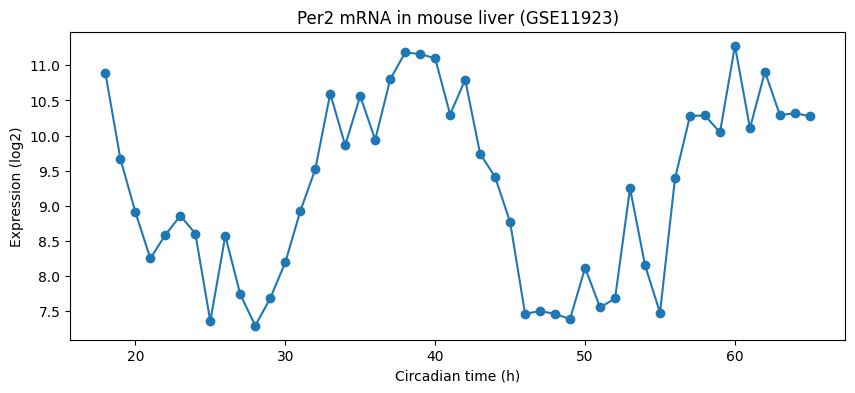

In [34]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(clock.columns, clock.loc["Per2"], marker="o")
ax.set_xlabel("Circadian time (h)")
ax.set_ylabel("Expression (log2)")
ax.set_title("Per2 mRNA in mouse liver (GSE11923)")
plt.show()

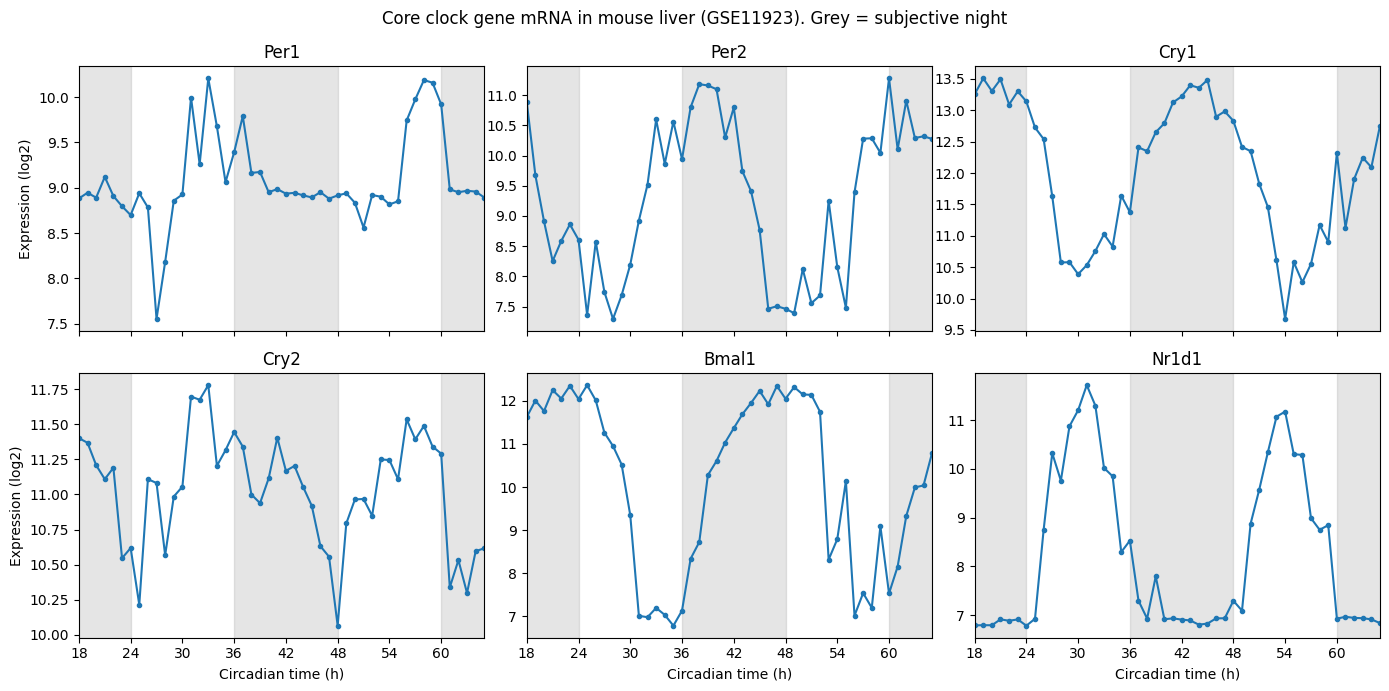

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)

for ax, gene in zip(axes.flatten(), clock.index):
    for start in [12, 36, 60]:
        ax.axvspan(start, start + 12, color="grey", alpha=0.2)
    ax.plot(clock.columns, clock.loc[gene], marker="o", markersize=3)
    ax.set_title(gene)
    ax.set_xlim(18, 65)
    ax.set_xticks(range(18, 66, 6))

for ax in axes[:, 0]:
    ax.set_ylabel("Expression (log2)")
for ax in axes[1]:
    ax.set_xlabel("Circadian time (h)")

fig.suptitle("Core clock gene mRNA in mouse liver (GSE11923). Grey = subjective night")
fig.tight_layout()
fig.savefig("clock_genes.png", dpi=200, bbox_inches="tight")
plt.show()

### Observations
All six core clock genes show clear ~24-hour oscillations in mRNA levels over both cycles, even though the mice were in constant darkness, so the rhythms are generated internally rather than driven by light.

The genes peak in a sequence rather than in two opposing groups: *Nr1d1* (REV-ERBα) peaks earliest (CT6–7), followed by *Per1* and *Cry2* (CT8–10), then *Per2* (CT13–15), and finally *Cry1* and *Bmal1* (*Arntl*) late in the subjective night (CT18–24).

Each rise in *Nr1d1* is followed a few hours later by a fall in *Bmal1*, consistent with REV-ERBα repressing *Bmal1* transcription.

Although both cryptochromes are repressors in the same loop, *Cry1* shows a strong rhythm peaking late in the subjective night, while *Cry2* shows a weak rhythm peaking in the subjective day.

Caveats: peak times are estimated by eye from noisy data (step 4 estimates them with cosinor regression), and these are mRNA levels, which don't directly reflect protein abundance or activity.